# Seminar 5 – EDA: `students_two.csv`
Profile of structure, quality, distributions and relationships with `Grade`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("data/students_two.csv")
df.head()

,Id,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,5001,21,Other,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,5002,20,Other,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,5003,21,State,50%,No,No,Private,2,Never,No,No,No,Yes,AA
3,5004,18,Private,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,5005,22,Private,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


## 1. Structure

In [2]:
print(f"Rows: {df.shape[0]:,}  Columns: {df.shape[1]}")
print("Id unique (primary key):", df["Id"].is_unique)
print("Duplicate rows:", df.duplicated().sum())
df.dtypes.to_frame("dtype").join(df.nunique().rename("n_unique"))

Rows: 145  Columns: 14
Id unique (primary key): True
Duplicate rows: 0


,dtype,n_unique
Id,int64,145
Student_Age,int64,9
High_School_Type,str,3
Scholarship,str,4
Additional_Work,str,2
Sports_activity,str,2
Transportation,str,2
Weekly_Study_Hours,int64,4
Attendance,str,4
Reading,str,2


In [3]:
id_cols = ["Id"]
metric_cols = ["Student_Age", "Weekly_Study_Hours"]
cat_cols = [c for c in df.columns if c not in id_cols + metric_cols]
print("Metrics:", metric_cols)
print("Categorical:", cat_cols)

Metrics: ['Student_Age', 'Weekly_Study_Hours']
Categorical: ['High_School_Type', 'Scholarship', 'Additional_Work', 'Sports_activity', 'Transportation', 'Attendance', 'Reading', 'Notes', 'Listening_in_Class', 'Project_work', 'Grade']


## 2. Data quality

In [4]:
quality = pd.DataFrame({
    "nulls": df.isna().sum(),
    "null_rate_%": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
quality["completeness"] = pd.cut(
    100 - quality["null_rate_%"], [-1, 80, 95, 99, 100.01],
    labels=["Sparse", "Incomplete", "Mostly complete", "Complete"])
quality

,nulls,null_rate_%,n_unique,completeness
Id,0,0.00,145,Complete
Student_Age,0,0.00,9,Complete
High_School_Type,0,0.00,3,Complete
Scholarship,1,0.69,4,Complete
Additional_Work,0,0.00,2,Complete
Sports_activity,0,0.00,2,Complete
Transportation,0,0.00,2,Complete
Weekly_Study_Hours,0,0.00,4,Complete
Attendance,0,0.00,4,Complete
Reading,0,0.00,2,Complete


In [5]:
# Value counts for every categorical column - spot placeholder / stray values
for c in cat_cols:
    print(f"--- {c} ---")
    print(df[c].value_counts(dropna=False).to_string(), "\n")

--- High_School_Type ---
High_School_Type
State      103
Private     25
Other       17 

--- Scholarship ---
Scholarship
50%     76
75%     42
100%    23
25%      3
NaN      1 

--- Additional_Work ---
Additional_Work
No     96
Yes    49 

--- Sports_activity ---
Sports_activity
No     87
Yes    58 

--- Transportation ---
Transportation
Private    84
Bus        61 

--- Attendance ---
Attendance
Always       98
Sometimes    25
Never        21
3             1 

--- Reading ---
Reading
No     76
Yes    69 

--- Notes ---
Notes
Yes    77
No     66
6       2 

--- Listening_in_Class ---
Listening_in_Class
Yes    75
No     69
6       1 

--- Project_work ---
Project_work
No     73
Yes    72 

--- Grade ---
Grade
AA      35
BA      24
BB      21
CC      17
DD      17
DC      13
CB      10
Fail     8 



**Issues spotted**
- `Attendance` contains a stray `'3'`; `Notes` and `Listening_in_Class` contain a stray `'6'` (numeric values in Yes/No / frequency fields – likely entry errors).
- `Scholarship` has 1 missing value.
- `Scholarship` is stored as text (`'50%'`) – convert to numeric for analysis.

In [6]:
# Rows affected by the invalid values
bad = (df["Attendance"].eq("3") | df["Notes"].eq("6")
       | df["Listening_in_Class"].eq("6") | df["Scholarship"].isna())
df[bad]

,Id,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
60,5061,19,State,50%,No,No,Private,12,Sometimes,Yes,6,Yes,No,BA
77,5078,18,Private,25%,No,No,Bus,2,Sometimes,No,6,No,Yes,DD
93,5094,18,State,NaN,Yes,No,Bus,0,Always,No,Yes,No,No,CB
112,5113,20,Other,50%,Yes,No,Private,0,3,No,Yes,Yes,Yes,BA
126,5127,18,Private,75%,Yes,Yes,Bus,12,Sometimes,No,Yes,6,Yes,BB


In [7]:
# Cleaned copy: invalid categories -> NaN, scholarship -> numeric
clean = df.copy()
clean.loc[~clean["Attendance"].isin(["Always", "Sometimes", "Never"]), "Attendance"] = np.nan
for c in ["Notes", "Listening_in_Class"]:
    clean.loc[~clean[c].isin(["Yes", "No"]), c] = np.nan
clean["Scholarship_pct"] = clean["Scholarship"].str.rstrip("%").astype(float)

grade_order = ["Fail", "DD", "DC", "CC", "CB", "BB", "BA", "AA"]
clean["Grade"] = pd.Categorical(clean["Grade"], categories=grade_order, ordered=True)
clean.isna().sum()[lambda s: s > 0]

Scholarship           1
Attendance            1
Notes                 2
Listening_in_Class    1
Scholarship_pct       1
dtype: int64

## 3. Numeric columns

In [8]:
num = ["Student_Age", "Weekly_Study_Hours", "Scholarship_pct"]
stats = clean[num].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
stats["skew"] = clean[num].skew()
stats["zeros"] = (clean[num] == 0).sum()
stats.round(2)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,zeros
Student_Age,145.0,19.68,1.99,18.0,18.0,18.0,18.0,19.0,21.0,24.0,25.56,26.0,1.12,0
Weekly_Study_Hours,145.0,2.33,4.25,0.0,0.0,0.0,0.0,0.0,2.0,12.0,12.00,12.0,1.70,93
Scholarship_pct,144.0,64.76,19.48,25.0,25.0,50.0,50.0,50.0,75.0,100.0,100.00,100.0,0.59,0


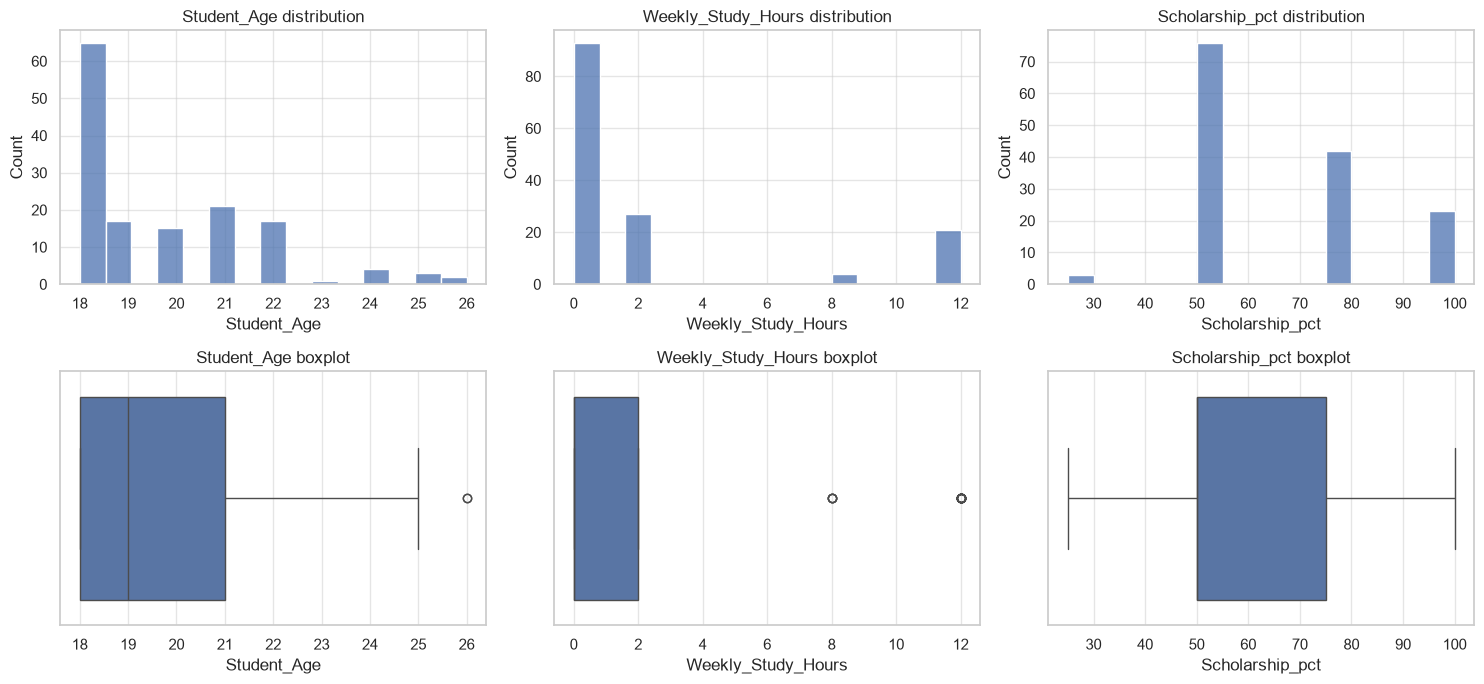

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes[0], num):
    sns.histplot(clean[c], bins=15, kde=False, ax=ax); ax.set_title(f"{c} distribution")
for ax, c in zip(axes[1], num):
    sns.boxplot(x=clean[c], ax=ax); ax.set_title(f"{c} boxplot")
plt.tight_layout(); plt.show()

In [10]:
# IQR outliers
for c in num:
    q1, q3 = clean[c].quantile([.25, .75]); iqr = q3 - q1
    out = clean[(clean[c] < q1 - 1.5*iqr) | (clean[c] > q3 + 1.5*iqr)]
    print(f"{c}: {len(out)} outliers", sorted(out[c].unique()))

Student_Age: 2 outliers [np.int64(26)]
Weekly_Study_Hours: 25 outliers [np.int64(8), np.int64(12)]
Scholarship_pct: 0 outliers []


`Weekly_Study_Hours` is heavily right-skewed with a median of 0 – most students report no study time, so means are misleading; prefer medians / bins.

## 4. Categorical columns

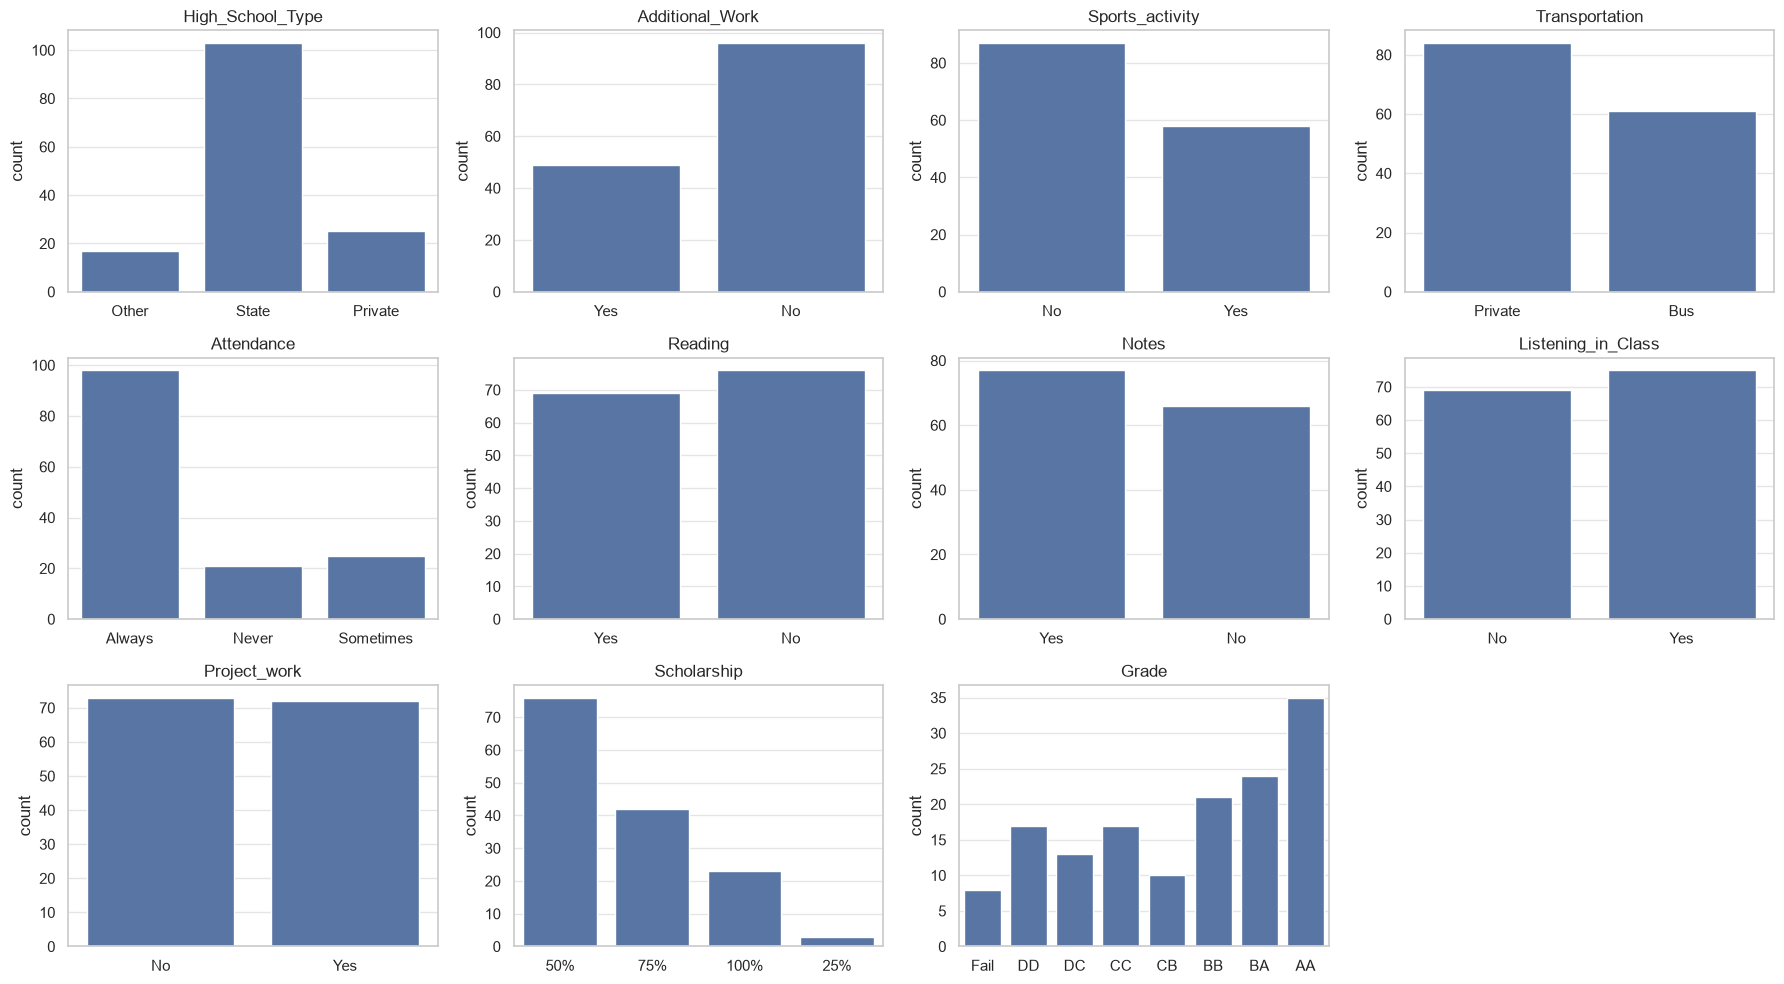

In [11]:
cats = [c for c in cat_cols if c not in ("Grade", "Scholarship")]
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, c in zip(axes.ravel(), cats + ["Scholarship", "Grade"]):
    order = grade_order if c == "Grade" else None
    sns.countplot(data=clean, x=c, order=order, ax=ax)
    ax.set_title(c); ax.set_xlabel("")
for ax in axes.ravel()[len(cats) + 2:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Relationships with Grade

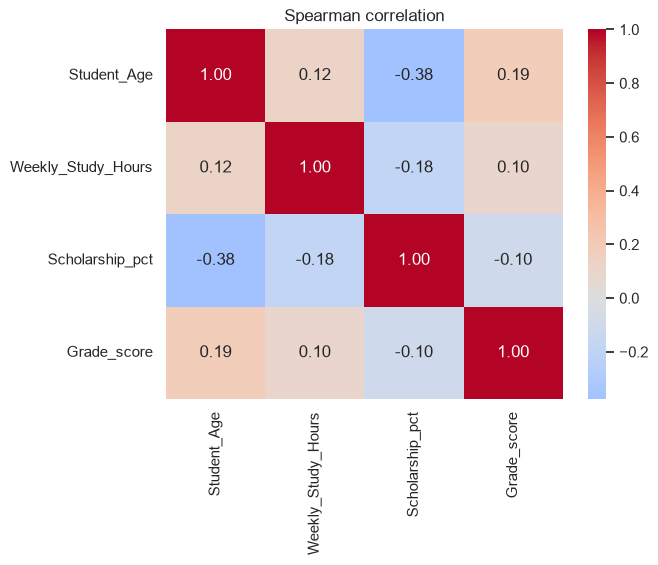

In [12]:
clean["Grade_score"] = clean["Grade"].cat.codes   # ordinal: Fail=0 ... AA=7
corr = clean[["Student_Age", "Weekly_Study_Hours", "Scholarship_pct", "Grade_score"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation"); plt.show()

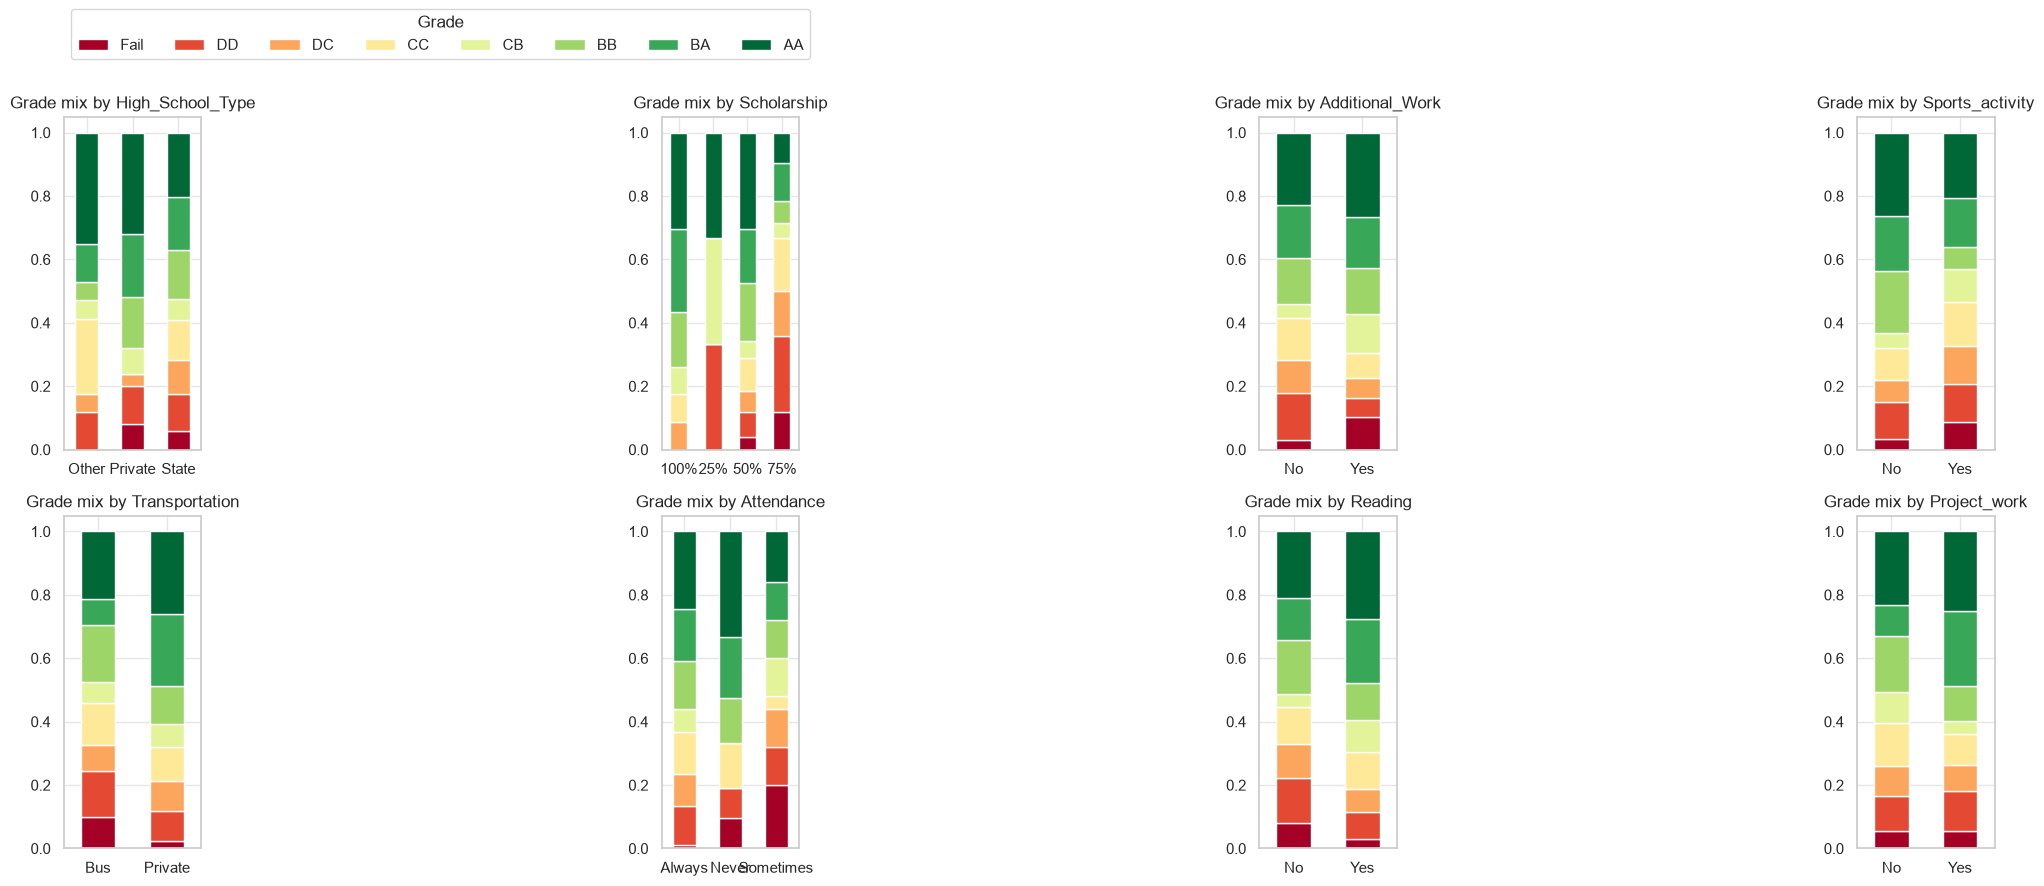

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, c in zip(axes.ravel(), ["High_School_Type", "Scholarship", "Additional_Work", "Sports_activity",
                                "Transportation", "Attendance", "Reading", "Project_work"]):
    ct = pd.crosstab(clean[c], clean["Grade"], normalize="index")
    ct.plot(kind="bar", stacked=True, ax=ax, colormap="RdYlGn", legend=False)
    ax.set_title(f"Grade mix by {c}"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
axes[0, 0].legend(title="Grade", bbox_to_anchor=(0, 1.15), loc="lower left", ncol=8)
plt.tight_layout(); plt.show()

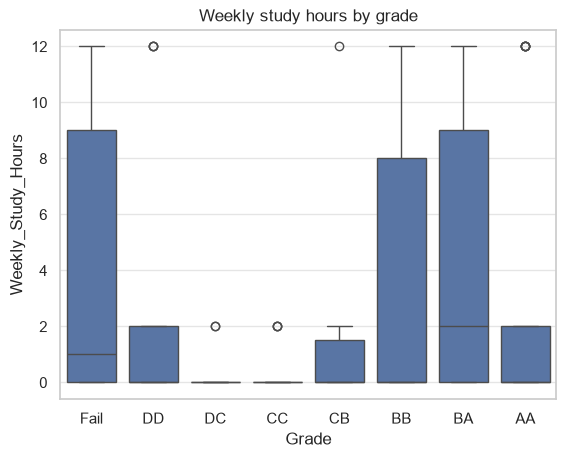

Student_Age        Weekly_Study_Hours        Scholarship_pct       
             mean median               mean median            mean median
Grade                                                                    
Fail        18.75   18.0               4.25    1.0           65.62   75.0
DD          18.76   18.0               2.47    0.0           63.24   75.0
DC          19.62   20.0               0.31    0.0           69.23   75.0
CC          19.71   19.0               0.35    0.0           66.18   75.0
CB          19.30   19.0               1.60    0.0           63.89   50.0
BB          20.33   19.0               3.14    0.0           63.10   50.0
BA          19.79   19.0               3.83    2.0           67.71   50.0
AA          20.00   20.0               2.23    0.0           62.14   50.0

In [14]:
sns.boxplot(data=clean, x="Grade", y="Weekly_Study_Hours", order=grade_order)
plt.title("Weekly study hours by grade"); plt.show()
clean.groupby("Grade", observed=True)[["Student_Age", "Weekly_Study_Hours", "Scholarship_pct"]].agg(["mean", "median"]).round(2)

In [15]:
# Association strength (Cramer's V) between each categorical feature and Grade
from scipy.stats import chi2_contingency
def cramers_v(x, y):
    t = pd.crosstab(x, y); chi2 = chi2_contingency(t)[0]; n = t.values.sum()
    return np.sqrt(chi2 / (n * (min(t.shape) - 1)))
pd.Series({c: cramers_v(clean[c], clean["Grade"]) for c in cats + ["Scholarship"]}).sort_values(ascending=False).round(3).to_frame("cramers_v_vs_Grade")

,cramers_v_vs_Grade
Notes,0.302
Scholarship,0.276
Attendance,0.276
Transportation,0.267
Additional_Work,0.258
Sports_activity,0.251
Listening_in_Class,0.236
Project_work,0.230
Reading,0.229
High_School_Type,0.195
